# Data Ingestion with dlt

**Ingestion** copies data from sources (APIs, databases, files) into the raw layer of the warehouse. Writing it by hand means handling pagination, schemas, types, nested JSON, incremental loading and retries. **dlt** (data load tool) is an open-source Python library that does this: you write a generator that yields records, dlt infers the schema, normalises nested data and loads it into DuckDB, PostgreSQL, BigQuery, Snowflake and others.

**After this lesson you can:**

1. Load data from a REST API with a dlt resource and pipeline.
2. Understand schema inference, normalisation of nested data, and schema evolution.
3. Load incrementally with a cursor and merge (upsert) without duplicates.
4. Inspect load packages and pipeline state.

**Data:** hourly historical weather for New York from the free **Open-Meteo** archive API (no key required) and NYC taxi trips.

In [1]:
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.mkdtemp())                   # all warehouses and projects of this lesson live here

import json
import urllib.parse
import urllib.request

import warnings

import dlt

warnings.filterwarnings("ignore", message="The inplace keyword")       # a pandas 3 deprecation inside a library

def connect(read_only: bool = False) -> duckdb.DuckDBPyConnection:
    """Open the ingestion database with UTC session time, so timestamps are shown as loaded (New York local time)."""
    con = duckdb.connect(str(DB), read_only=read_only)
    con.execute("SET TimeZone = 'UTC'")
    return con

print("dlt", dlt.__version__)
OPEN_METEO = "https://archive-api.open-meteo.com/v1/archive"
NYC = {"latitude": 40.71, "longitude": -74.01}

dlt 1.32.0


## 1. A Resource and a Pipeline

- A **resource** is a Python generator (or function) that yields records (dicts or lists of dicts).
- A **pipeline** moves the records to a **destination** into a **dataset** (schema). `pipeline.run()` does extract → normalise → load.

In [2]:
def fetch_weather(start: str, end: str) -> dict:
    params = {**NYC, "start_date": start, "end_date": end, "timezone": "America/New_York",
              "hourly": "temperature_2m,precipitation,snowfall,wind_speed_10m"}
    with urllib.request.urlopen(f"{OPEN_METEO}?{urllib.parse.urlencode(params)}", timeout=60) as r:
        return json.load(r)

@dlt.resource(name="weather_hourly", write_disposition="replace")
def weather(start: str = "2024-01-01", end: str = "2024-01-31"):
    data = fetch_weather(start, end)
    h = data["hourly"]
    for i, ts in enumerate(h["time"]):
        yield {"observed_at": ts, **{k: h[k][i] for k in h if k != "time"},
               "location": {"lat": data["latitude"], "lon": data["longitude"], "timezone": data["timezone"]}}

DB = WORK / "ingest.duckdb"
pipe = dlt.pipeline(pipeline_name="nyc_weather", destination=dlt.destinations.duckdb(str(DB)), dataset_name="raw_weather",
                    pipelines_dir=str(WORK / "dlt_pipelines"))
info = pipe.run(weather())
print("load finished without failed jobs:", not info.has_failed_jobs)
con = connect(read_only=True)
print(con.sql("SHOW ALL TABLES").df()[["schema", "name"]])

load finished without failed jobs: True
        schema                 name
0  raw_weather           _dlt_loads
1  raw_weather  _dlt_pipeline_state
2  raw_weather         _dlt_version
3  raw_weather       weather_hourly


dlt created the table `weather_hourly` **and** its own bookkeeping tables (`_dlt_loads`, `_dlt_version`, `_dlt_pipeline_state`). The nested `location` dict was **flattened** into columns `location__lat`, `location__lon`, ...

In [3]:
cols = con.sql("DESCRIBE raw_weather.weather_hourly").df()[["column_name", "column_type"]]
print(cols.to_string(index=False))
print(con.sql("SELECT min(observed_at), max(observed_at), count(*) FROM raw_weather.weather_hourly").df())
con.close()

       column_name              column_type
       observed_at TIMESTAMP WITH TIME ZONE
    temperature_2m                   DOUBLE
     precipitation                   DOUBLE
          snowfall                   DOUBLE
    wind_speed_10m                   DOUBLE
     location__lat                   DOUBLE
     location__lon                   DOUBLE
location__timezone                  VARCHAR
      _dlt_load_id                  VARCHAR
           _dlt_id                  VARCHAR
           min(observed_at)          max(observed_at)  count_star()
0 2024-01-01 00:00:00+00:00 2024-01-31 23:00:00+00:00           744


## 2. Nested Lists Become Child Tables

JSON often contains lists inside records. dlt normalises them into **child tables** linked to the parent with `_dlt_parent_id`, the relational form that a warehouse can query efficiently.

In [4]:
@dlt.resource(name="daily_summary", write_disposition="replace")
def daily(start: str = "2024-01-01", end: str = "2024-01-31"):
    h = fetch_weather(start, end)["hourly"]
    df = pd.DataFrame(h).assign(day=lambda d: d["time"].str[:10])
    for day, part in df.groupby("day"):
        yield {"day": day, "max_temp": float(part["temperature_2m"].max()), "snow_cm": float(part["snowfall"].sum()),  # plain floats:
               "hours": [{"hour": int(t[11:13]), "temp": float(v)} for t, v in zip(part["time"], part["temperature_2m"])]}  # no numpy types

pipe.run(daily())
con = connect(read_only=True)
print(con.sql("SELECT table_name FROM information_schema.tables WHERE table_schema = 'raw_weather' AND table_name LIKE 'daily%'").df())
print(con.sql("""SELECT d.day, count(*) AS hourly_rows FROM raw_weather.daily_summary d
                 JOIN raw_weather.daily_summary__hours h ON h._dlt_parent_id = d._dlt_id GROUP BY d.day ORDER BY d.day LIMIT 3""").df())
con.close()

             table_name
0         daily_summary
1  daily_summary__hours
          day  hourly_rows
0  2024-01-01           24
1  2024-01-02           24
2  2024-01-03           24


## 3. Incremental Loading with Merge

Re-loading everything on every run wastes time and API calls. An **incremental** resource remembers a cursor (the last loaded timestamp) in the pipeline **state**, and `write_disposition="merge"` with a `primary_key` upserts rows, so overlapping loads create no duplicates.

In [5]:
@dlt.resource(name="weather_incremental", write_disposition="merge", primary_key="observed_at")
def weather_inc(observed_at=dlt.sources.incremental("observed_at", initial_value="2024-01-01T00:00")):
    start = observed_at.last_value[:10]                          # resume from the last loaded day (overlap is fine: merge)
    end = min(pd.Timestamp(start) + pd.Timedelta(days=13), pd.Timestamp("2024-02-29")).strftime("%Y-%m-%d")
    h = fetch_weather(start, end)["hourly"]
    for i, ts in enumerate(h["time"]):
        yield {"observed_at": ts, "temperature_2m": h["temperature_2m"][i], "snowfall": h["snowfall"][i]}

log = []
for run in range(1, 6):
    pipe.run(weather_inc())
    con = connect(read_only=True)
    n, lo, hi = con.sql("SELECT count(*), min(observed_at), max(observed_at) FROM raw_weather.weather_incremental").fetchone()
    dups = con.sql("SELECT count(*) - count(DISTINCT observed_at) FROM raw_weather.weather_incremental").fetchone()[0]
    con.close()
    log.append({"run": run, "rows": n, "from": str(lo)[:16], "to": str(hi)[:16], "duplicates": dups})
pd.DataFrame(log)

,run,rows,from,to,duplicates
0,1,336,2024-01-01 00:00,2024-01-14 23:00,0
1,2,648,2024-01-01 00:00,2024-01-27 23:00,0
2,3,960,2024-01-01 00:00,2024-02-09 23:00,0
3,4,1272,2024-01-01 00:00,2024-02-22 23:00,0
4,5,1440,2024-01-01 00:00,2024-02-29 23:00,0


Each run continues where the previous one stopped (the cursor is stored in `_dlt_pipeline_state`), the windows overlap by one day, and the merge keeps exactly one row per hour.

## 4. Schema Evolution

When a source adds a field, dlt adds the column automatically and records a new schema version. Schema **contracts** can instead freeze the schema and reject unexpected changes.

In [6]:
@dlt.resource(name="weather_hourly", write_disposition="append")
def weather_v2():
    h = fetch_weather("2024-02-01", "2024-02-02")["hourly"]
    for i, ts in enumerate(h["time"]):
        yield {"observed_at": ts, "temperature_2m": h["temperature_2m"][i], "feels_cold": h["temperature_2m"][i] < 0}   # new field

pipe.run(weather_v2())
con = connect(read_only=True)
print("new column added:", "feels_cold" in con.sql("DESCRIBE raw_weather.weather_hourly").df()["column_name"].tolist())
print(con.sql("SELECT version, engine_version, inserted_at FROM raw_weather._dlt_version ORDER BY inserted_at").df()[["version"]].T)
con.close()

@dlt.resource(name="weather_hourly", write_disposition="append", schema_contract={"columns": "freeze"})
def weather_v3():
    yield {"observed_at": "2024-02-03T00:00", "temperature_2m": 1.0, "humidity": 80}                      # another new field

try:
    pipe.run(weather_v3())
except Exception as err:
    print("frozen contract rejected the change:", type(err).__name__)

new column added: True
         0  1  2  3
version  2  4  6  8
frozen contract rejected the change: PipelineStepFailed


## 5. Combine with Other Sources: Weather Meets Taxi Demand

Ingested data becomes valuable when combined. The warehouse now has hourly weather; joined with hourly taxi demand, it answers "how does snow change taxi demand?".

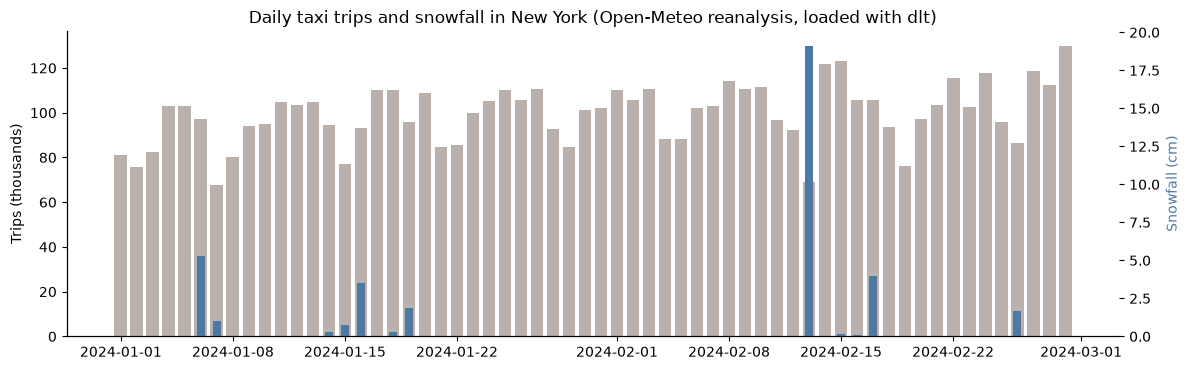

snowiest day: 2024-02-13 (19.1 cm) with 69,067 trips; median day: 102,297 trips


In [7]:
con = connect()
con.execute(f"""
CREATE OR REPLACE TABLE hourly_demand AS
SELECT date_trunc('hour', tpep_pickup_datetime) AS hour, count(*) AS trips
FROM read_parquet({[str(datasets.taxi(m)) for m in ['2024-01', '2024-02']]})
WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-03-01'
GROUP BY 1
""")
joined = con.sql("""
SELECT d.hour, d.trips, w.temperature_2m, w.snowfall
FROM hourly_demand d JOIN raw_weather.weather_incremental w ON CAST(w.observed_at AS TIMESTAMP) = d.hour
""").df()
con.close()
daily_j = joined.set_index("hour").resample("D").agg({"trips": "sum", "snowfall": "sum", "temperature_2m": "mean"})
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(daily_j.index, daily_j["trips"] / 1000, color="#BAB0AC", label="trips per day (thousands)")
ax2 = ax.twinx()
ax2.bar(daily_j.index, daily_j["snowfall"], color="#4E79A7", width=0.5, label="snowfall (cm)")
ax.set(title="Daily taxi trips and snowfall in New York (Open-Meteo reanalysis, loaded with dlt)", ylabel="Trips (thousands)")
ax2.set_ylabel("Snowfall (cm)", color="#4E79A7")
plt.tight_layout()
plt.show()
snowiest = daily_j["snowfall"].idxmax()
print(f"snowiest day: {snowiest.date()} ({daily_j.loc[snowiest, 'snowfall']:.1f} cm) with {daily_j.loc[snowiest, 'trips']:,.0f} trips; "
      f"median day: {daily_j['trips'].median():,.0f} trips")

The snowiest day in the data, 13 February 2024, had far fewer trips than a typical day: city schools switched to remote learning, and many people stayed home.

*Insight: Let a library handle the mechanics of ingestion (schemas, nesting, state, merges) and spend your effort on the source logic. Load incrementally with a cursor and a merge key, keep raw data as delivered, and decide explicitly whether schema changes are accepted or rejected.*

## Real-World Use Case or Analogy

An ingestion tool is like a **freight forwarder**: you hand over the goods (records), and they handle packaging, customs forms (schemas), splitting mixed shipments into separate containers (child tables) and remembering what was already delivered (state).

Data teams use dlt, Airbyte or Fivetran to copy data from SaaS APIs (CRM, payments, marketing tools) and production databases into the warehouse every hour; the transformations then happen in dbt.